**EfficientNet-B0**

STANDALONE: EfficientNetB0_Standalone_Dropout04_Trial | DEVICE: cuda
RECONSTRUCTED ORIGINAL HYBRID SPLIT
Classes: ['bird_dropping', 'clean', 'pine_pollen', 'plastic_bag', 'sand', 'shadow']
Training images: 1632 | Testing images: 685
Training dates: 5 | Testing dates: 3
Split file saved: /kaggle/working/standalone_results/EfficientNetB0_Standalone_Dropout04_Trial/efficientnetb0_standalone_dropout04_trial_reconstructed_split_manifest.csv
NOTE: Exact agreement with your selected hybrid can be proven only by comparing its saved split manifest or image lists.
Training-only selection: recording-session groups 1307 325


EfficientNetB0_Standalone_Dropout04_Trial training:   0%|          | 0/82 [00:00<?, ?it/s]

SELECTION epoch 01 | Training 89.90% | Training-only holdout 81.54%


EfficientNetB0_Standalone_Dropout04_Trial training:   0%|          | 0/82 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7dc86c18c900>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7dc86c18c900>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

SELECTION epoch 02 | Training 97.25% | Training-only holdout 86.15%


... (22 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7dc86c18c900>Exception ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x7dc86c18c900>Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Traceback (most recent call last):
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
self._shutdown_workers()    self._shutdown_workers()

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
        if w.is_alive():
if w.is_alive():  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        assert self._parent_pid == os.getpid(), 'can only te

FINAL epoch 03 | TRAINING ACCURACY: 97.00%


EfficientNetB0_Standalone_Dropout04_Trial training:   0%|          | 0/102 [00:00<?, ?it/s]

FINAL epoch 04 | TRAINING ACCURACY: 98.47%

EfficientNetB0_Standalone_Dropout04_Trial — FINAL STANDALONE RESULTS
TRAINING ACCURACY: 98.90%
TESTING ACCURACY : 94.31%
TEST MACRO-F1    : 92.27%
TEST PRECISION   : 95.93%
TEST RECALL      : 90.74%
GENERALIZATION GAP: 4.59 percentage points
               precision    recall  f1-score   support

bird_dropping       1.00      0.97      0.99        77
        clean       0.85      1.00      0.92       181
  pine_pollen       0.98      1.00      0.99       176
  plastic_bag       0.93      0.93      0.93        45
         sand       0.99      0.96      0.97       138
       shadow       1.00      0.57      0.73        68

     accuracy                           0.94       685
    macro avg       0.96      0.91      0.92       685
 weighted avg       0.95      0.94      0.94       685



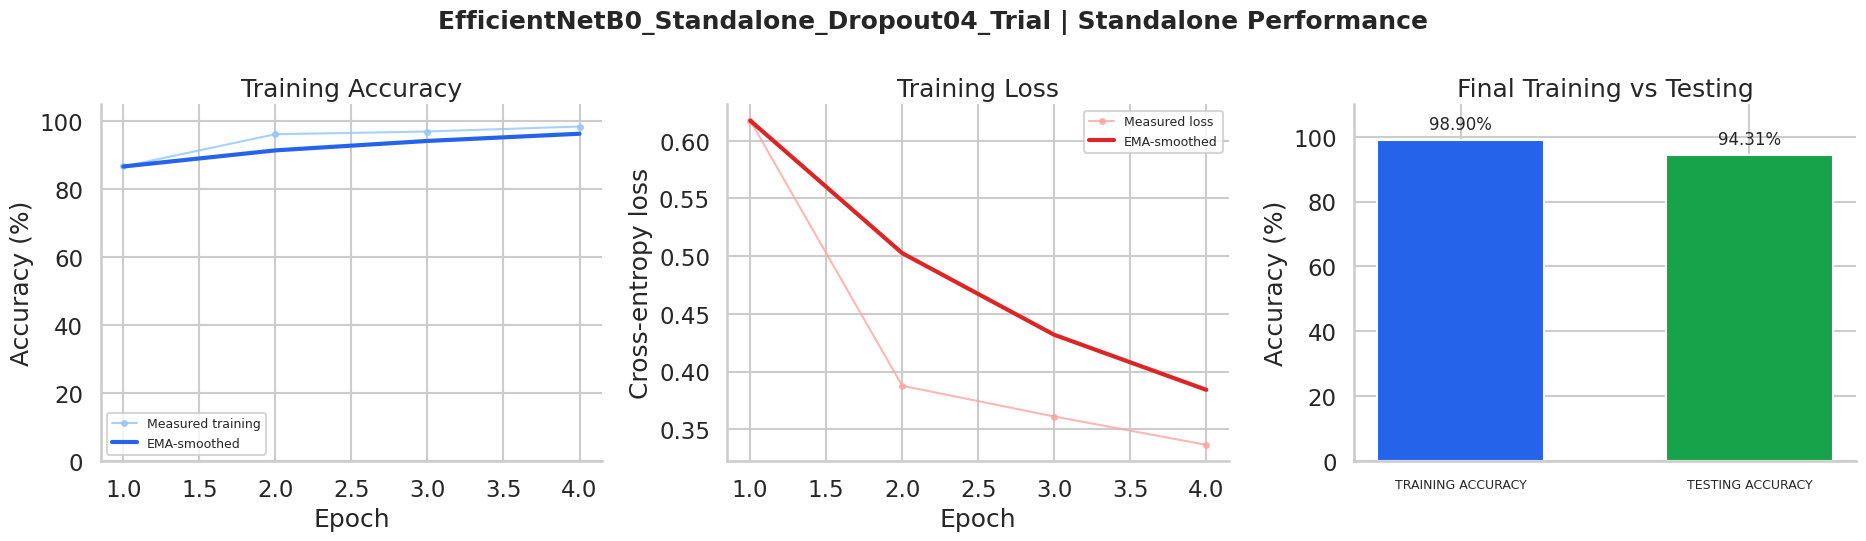

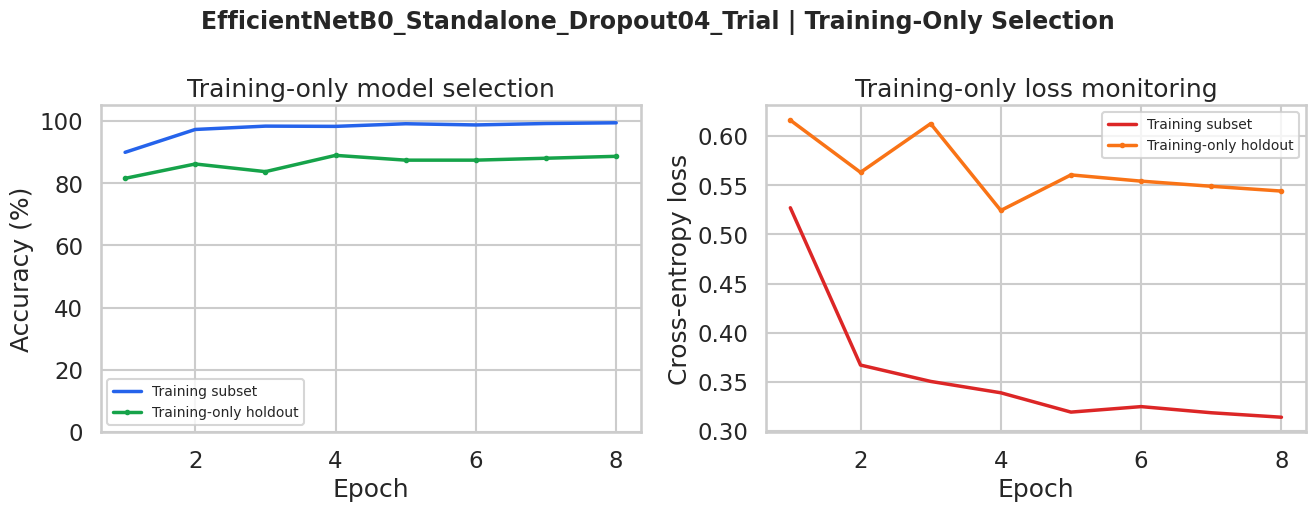

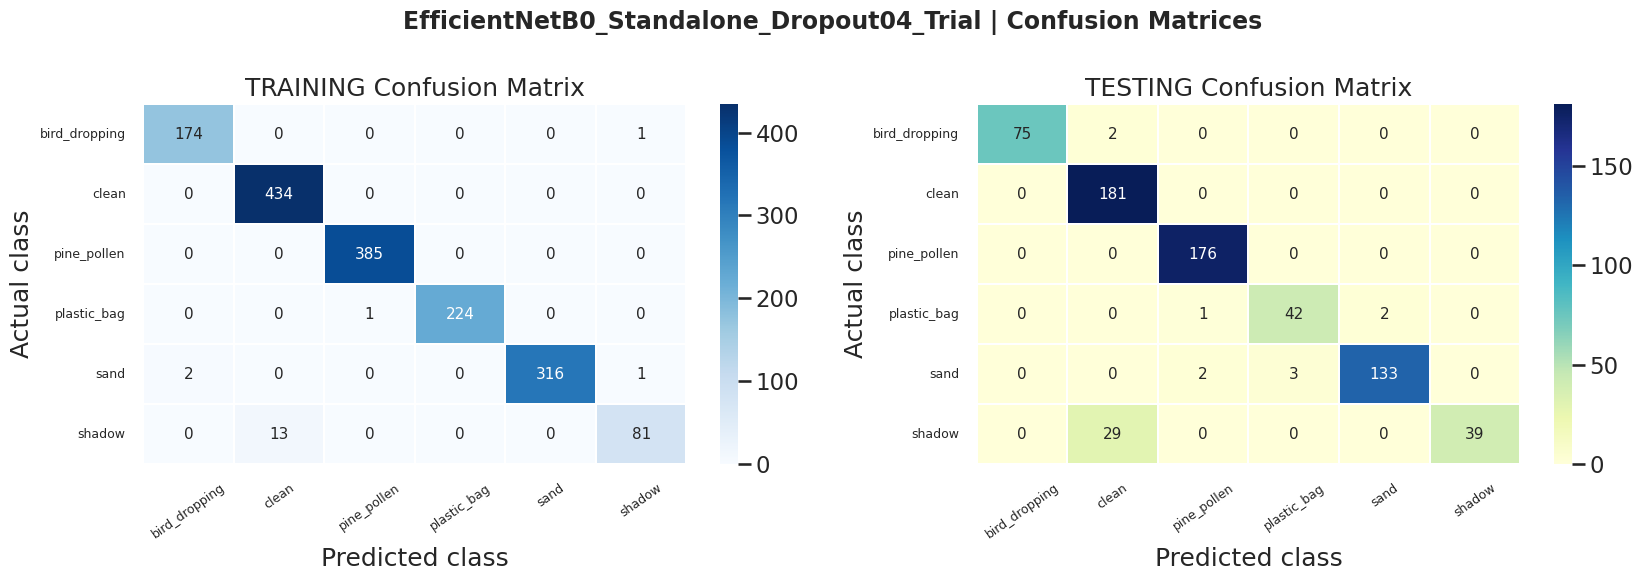


SAVED RESULTS: /kaggle/working/standalone_results/EfficientNetB0_Standalone_Dropout04_Trial
Individual PNG downloads:


/kaggle/working/standalone_results/EfficientNetB0_Standalone_Dropout04_Trial/efficientnetb0_standalone_dropout04_trial_accuracy_graphs.png

/kaggle/working/standalone_results/EfficientNetB0_Standalone_Dropout04_Trial/efficientnetb0_standalone_dropout04_trial_confusion_matrices.png

/kaggle/working/standalone_results/EfficientNetB0_Standalone_Dropout04_Trial/efficientnetb0_standalone_dropout04_trial_training_only_selection.png

Metrics and history saved in same directory.


In [4]:
# ==============================================================
# EFFICIENTNET-B0 STANDALONE 
# ==============================================================
import gc, json, time, random, hashlib, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torchvision import models, transforms
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, confusion_matrix, classification_report)
from tqdm.auto import tqdm
from IPython.display import display, FileLink

NAME = "EfficientNetB0_Standalone_Dropout04_Trial"
PREFIX = "efficientnetb0_standalone_dropout04_trial"
SEED = 42
BATCH_SIZE = 16
HEAD_EPOCHS = 5
MAX_FINETUNE_EPOCHS = 20
PATIENCE = 4
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DATA_ROOT = Path('/kaggle/input/datasets/umirzakovasabina/cbnu-solarpower/CBNU-SolarPowerdataset')
IMAGE_DIR = DATA_ROOT / 'SoilingImage' / 'crop'
OUT = Path('/kaggle/working/standalone_results') / NAME
OUT.mkdir(parents=True, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
print('STANDALONE:', NAME, '| DEVICE:', DEVICE)

# ---------------- 1. RECONSTRUCT ORIGINAL HYBRID SPLIT FROM CBNU ----------------
# No previous Kaggle outputs or hybrid model files are needed.
# Match CSV by (panel number, YYYYMMDDHHMM) and sort by full image path,
# exactly as in the selected GoogLeNet + EfficientNet hybrid script.
import re
CSV_PATH = DATA_ROOT / 'weather-solarpowergeneration.csv'
if not IMAGE_DIR.is_dir() or not CSV_PATH.is_file():
    raise FileNotFoundError(f'Original CBNU input missing: {IMAGE_DIR} or {CSV_PATH}')
meta = pd.read_csv(CSV_PATH, encoding='cp949')
if not {'Panel number', 'Time', 'Soiling type'}.issubset(meta.columns):
    raise ValueError('Missing required metadata columns in CBNU CSV')
paths = sorted(p for p in IMAGE_DIR.iterdir()
               if p.is_file() and p.suffix.lower() in {'.jpg', '.jpeg', '.png'})
filename_regex = re.compile(r'^panel(?P<panel>\d+)_NVR_ch\d+_jpg_(?P<stamp>\d{14})$', re.I)
lookup = {}
for p in paths:
    match = filename_regex.fullmatch(p.stem)
    if match is None:
        raise ValueError(f'Unexpected image filename: {p.name}')
    key = (int(match['panel']), match['stamp'][:12])
    if key in lookup:
        raise ValueError(f'Ambiguous panel/timestamp key: {key}')
    lookup[key] = str(p)
rows = []
for _, row in meta.iterrows():
    stamp = pd.to_datetime(row['Time'], errors='coerce')
    if pd.isna(stamp) or pd.isna(row['Panel number']) or pd.isna(row['Soiling type']):
        raise ValueError(f'Invalid metadata row: {row.to_dict()}')
    panel, minute = int(row['Panel number']), stamp.strftime('%Y%m%d%H%M')
    key = (panel, minute)
    if key not in lookup:
        raise ValueError(f'No matching image for {key}')
    rows.append({'path': lookup[key], 'class_name': str(row['Soiling type']).strip(),
                 'timestamp': minute, 'panel': panel, 'date': minute[:8]})
data = pd.DataFrame(rows).sort_values('path').reset_index(drop=True)
if len(data) != len(paths) or data.path.duplicated().any():
    raise RuntimeError('CSV and cropped panel images do not match one-to-one')
classes = sorted(data.class_name.unique().tolist())
if len(classes) != 6:
    raise RuntimeError(f'Expected six classes, found {classes}')
data['label'] = data.class_name.map({name: i for i, name in enumerate(classes)})

# Repeat the ORIGINAL hybrid's outer date-grouped split algorithm and seed.
def original_hybrid_outer_split(table, groups, target=.30, trials=1000, seed=SEED):
    splitter = GroupShuffleSplit(n_splits=trials, test_size=target, random_state=seed)
    best = None
    best_score = float('inf')
    population = table.label.value_counts(normalize=True)
    for train_ids, test_ids in splitter.split(table, table.label, groups=groups):
        tr, te = table.iloc[train_ids], table.iloc[test_ids]
        if tr.label.nunique() != 6 or te.label.nunique() != 6:
            continue
        a, b = tr.label.value_counts(normalize=True), te.label.value_counts(normalize=True)
        score = abs(len(te)/len(table) - target) + .08*sum(
            abs(a.get(c, 0) - population.get(c, 0)) +
            abs(b.get(c, 0) - population.get(c, 0)) for c in range(6))
        if score < best_score:
            best, best_score = (train_ids, test_ids), score
    return best

split_ids = original_hybrid_outer_split(data, data.date)
if split_ids is None:
    raise RuntimeError('Original date-grouped split cannot be recreated')
tr_ids, te_ids = split_ids
train_df, test_df = data.iloc[tr_ids].copy(), data.iloc[te_ids].copy()
if not set(train_df.date).isdisjoint(set(test_df.date)):
    raise RuntimeError('Date overlap between training and testing')
if set(train_df.path).intersection(set(test_df.path)):
    raise RuntimeError('Image path overlap between training and testing')

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as stream:
        for chunk in iter(lambda: stream.read(1024*1024), b''):
            digest.update(chunk)
    return digest.hexdigest()
image_hashes = {p: sha256_file(p) for p in data.path}
if not {image_hashes[p] for p in train_df.path}.isdisjoint(
           {image_hashes[p] for p in test_df.path}):
    raise RuntimeError('Exact image leakage across split')

# Save a newly reconstructed split record (not a stored previous result).
MANIFEST = OUT / f'{PREFIX}_reconstructed_split_manifest.csv'
manifest = data.copy()
manifest['sha256'] = manifest.path.map(image_hashes)
manifest['split'] = 'test'
manifest.loc[tr_ids, 'split'] = 'train'
manifest.to_csv(MANIFEST, index=False)
print('RECONSTRUCTED ORIGINAL HYBRID SPLIT')
print('Classes:', classes)
print(f'Training images: {len(train_df)} | Testing images: {len(test_df)}')
print(f'Training dates: {train_df.date.nunique()} | Testing dates: {test_df.date.nunique()}')
print('Split file saved:', MANIFEST)
print('NOTE: Exact agreement with your selected hybrid can be proven only by comparing its saved split manifest or image lists.')

# ---------------- 2. TRAIN-ONLY MODEL SELECTION ----------------
# Training-only grouped holdout; NOT a third permanent data partition.
def best_group_split(frame, group_values, target=.20, trials=600, seed=SEED+1):
    splitter = GroupShuffleSplit(n_splits=trials,test_size=target,random_state=seed)
    pop=frame.label.value_counts(normalize=True)
    best=None; best_score=float('inf')
    for i,j in splitter.split(frame,frame.label,groups=group_values):
        a,b=frame.iloc[i],frame.iloc[j]
        if a.label.nunique()!=6 or b.label.nunique()!=6: continue
        pa,pb=a.label.value_counts(normalize=True),b.label.value_counts(normalize=True)
        score=abs(len(b)/len(frame)-target)+.08*sum(
            abs(pa.get(c,0)-pop.get(c,0))+abs(pb.get(c,0)-pop.get(c,0)) for c in range(6))
        if score<best_score: best,best_score=(i,j),score
    return best

inner=best_group_split(train_df.reset_index(drop=True),train_df.date.reset_index(drop=True))
inner_method='whole-date groups'
if inner is None:
    tmp=train_df.copy()
    tmp['_dt']=pd.to_datetime(tmp.timestamp,format='%Y%m%d%H%M')
    tmp=tmp.sort_values(['panel','_dt']) if 'panel' in tmp.columns else tmp.sort_values('_dt')
    if 'panel' in tmp.columns:
        gap=tmp.groupby('panel')['_dt'].diff().dt.total_seconds().div(60)
        prior=tmp.groupby('panel')['_dt'].shift()
        group_ids=tmp['panel'].astype(str)
        start=gap.isna() | (gap>=60) | (tmp['_dt'].dt.date!=prior.dt.date)
        session=start.groupby(tmp['panel']).cumsum()
    else:
        gap=tmp['_dt'].diff().dt.total_seconds().div(60)
        start=gap.isna() | (gap>=60) | (tmp['_dt'].dt.date!=tmp['_dt'].shift().dt.date)
        session=start.cumsum(); group_ids=pd.Series('all',index=tmp.index)
    session_groups=(group_ids+'_'+session.astype(str)).reindex(train_df.index)
    inner=best_group_split(train_df.reset_index(drop=True),session_groups.reset_index(drop=True),
                           trials=1500)
    inner_method='recording-session groups'
USE_SELECTION=inner is not None
if USE_SELECTION:
    inner_train,inner_holdout=inner
    sel_train_df=train_df.iloc[inner_train].copy()
    sel_holdout_df=train_df.iloc[inner_holdout].copy()
    print('Training-only selection:',inner_method,len(sel_train_df),len(sel_holdout_df))
else:
    warnings.warn('No six-class grouped internal holdout possible; using fixed 5+10 epochs')
    sel_train_df=train_df.copy()
    sel_holdout_df=train_df.iloc[:0].copy()

# ---------------- 3. TRANSFORMS / LOADERS ----------------
normalization=transforms.Normalize([.485,.456,.406],[.229,.224,.225])
train_tf=transforms.Compose([
    transforms.Resize((224,224)),transforms.RandomHorizontalFlip(.5),
    transforms.RandomRotation(8),transforms.ColorJitter(brightness=.1,contrast=.1),
    transforms.ToTensor(),normalization])
eval_tf=transforms.Compose([
    transforms.Resize((224,224)),transforms.ToTensor(),normalization])

class CBNUSolar(Dataset):
    def __init__(self,frame,transform):
        self.frame=frame.reset_index(drop=True);self.transform=transform
    def __len__(self):return len(self.frame)
    def __getitem__(self,index):
        r=self.frame.iloc[index]
        with Image.open(r.path) as im: x=self.transform(im.convert('RGB'))
        return x,int(r.label)

def loader(frame,transform,shuffle=False):
    return DataLoader(CBNUSolar(frame,transform),batch_size=BATCH_SIZE,shuffle=shuffle,
                      num_workers=2,pin_memory=torch.cuda.is_available())
selection_train=loader(sel_train_df,train_tf,True)
selection_eval=loader(sel_holdout_df,eval_tf) if USE_SELECTION else None
final_train=loader(train_df,train_tf,True)
train_eval=loader(train_df,eval_tf)
test_eval=loader(test_df,eval_tf)

# ---------------- 4. INDEPENDENT STANDALONE ARCHITECTURE ----------------
# Explicit dropout 0.40; learning rates unchanged: head=0.002, fine-tune=2e-5.
class EfficientNetB0Standalone(nn.Module):
    def __init__(self):
        super().__init__()
        self.network=models.efficientnet_b0(
            weights=models.EfficientNet_B0_Weights.DEFAULT)
        in_features = self.network.classifier[1].in_features
        self.network.classifier = nn.Sequential(
            nn.Dropout(p=0.50),
            nn.Linear(in_features, 6)
        )
    def forward(self,x):return self.network(x)
    def configure_phase(self,phase):
        for p in self.parameters():p.requires_grad=False
        for p in self.network.classifier.parameters():p.requires_grad=True
        if phase=='Fine-Tuning':
            for p in self.network.features[-2:].parameters():p.requires_grad=True
    def stable_backbone(self):
        self.network.features.eval()
        self.network.classifier.train()

criterion=nn.CrossEntropyLoss(label_smoothing=.05)

def training_epoch(net,dataloader,optimizer,trainable):
    net.train();net.stable_backbone()
    correct=total=0;loss_total=0.
    for x,y in tqdm(dataloader,desc=NAME+' training',leave=False):
        x,y=x.to(DEVICE),y.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits=net(x)
        loss=criterion(logits,y)
        loss.backward()
        nn.utils.clip_grad_norm_(trainable,1.0)
        optimizer.step()
        correct+=(logits.argmax(1)==y).sum().item()
        total+=len(y);loss_total+=loss.item()*len(y)
    return loss_total/total,correct/total

@torch.inference_mode()
def quick_eval(net,dataloader):
    net.eval();correct=total=0;loss_total=0.
    for x,y in dataloader:
        x,y=x.to(DEVICE),y.to(DEVICE)
        logits=net(x)
        correct+=(logits.argmax(1)==y).sum().item()
        total+=len(y);loss_total+=criterion(logits,y).item()*len(y)
    return loss_total/total,correct/total

# ---------------- 5. TRAINING-ONLY EPOCH SELECTION ----------------
started=time.perf_counter()
selection_history=[]
if USE_SELECTION:
    selector=EfficientNetB0Standalone().to(DEVICE)
    best_loss=float('inf');best_epoch=None;bad=0
    for phase,epochs,lr in [('Feature Extraction',HEAD_EPOCHS,0.006),
                             ('Fine-Tuning',MAX_FINETUNE_EPOCHS,2e-7)]:
        selector.configure_phase(phase)
        trainable=[p for p in selector.parameters() if p.requires_grad]
        optimizer=torch.optim.AdamW(trainable,lr=lr,weight_decay=5e-4)
        scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=epochs)
        for _ in range(epochs):
            tl,ta=training_epoch(selector,selection_train,optimizer,trainable)
            vl,va=quick_eval(selector,selection_eval)
            scheduler.step()
            record=dict(epoch=len(selection_history)+1,phase=phase,
                        training_accuracy=ta,training_loss=tl,
                        holdout_accuracy=va,holdout_loss=vl)
            selection_history.append(record)
            print(f'SELECTION epoch {record["epoch"]:02d} | Training {ta*100:.2f}% '
                  f'| Training-only holdout {va*100:.2f}%')
            if vl<best_loss-0.0005:
                best_loss,best_epoch,bad=vl,record['epoch'],0
            else:bad+=1
            if phase=='Fine-Tuning' and bad>=PATIENCE:break
        if phase=='Fine-Tuning' and bad>=PATIENCE:break
    if best_epoch is None:raise RuntimeError('No training epoch selected')
    pd.DataFrame(selection_history).to_csv(OUT/f'{PREFIX}_training_only_selection_history.csv',index=False)
    del selector;gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()
else:
    best_epoch=HEAD_EPOCHS+10
    print('Fixed budget: 5 feature extraction + 10 fine-tuning epochs')

# ---------------- 6. FRESH FINAL TRAIN ON COMPLETE 70% ----------------
net=EfficientNetB0Standalone().to(DEVICE)
history=[]
phases=[('Feature Extraction',min(HEAD_EPOCHS,best_epoch),0.002),
        ('Fine-Tuning',max(0,best_epoch-HEAD_EPOCHS),2e-5)]
for phase,epochs,lr in phases:
    if not epochs:continue
    net.configure_phase(phase)
    trainable=[p for p in net.parameters() if p.requires_grad]
    optimizer=torch.optim.AdamW(trainable,lr=lr,weight_decay=5e-4)
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=epochs)
    for _ in range(epochs):
        loss,acc=training_epoch(net,final_train,optimizer,trainable)
        scheduler.step()
        record=dict(epoch=len(history)+1,phase=phase,training_loss=loss,training_accuracy=acc)
        history.append(record)
        print(f'FINAL epoch {record["epoch"]:02d} | TRAINING ACCURACY: {acc*100:.2f}%')

@torch.inference_mode()
def evaluate_final(dataloader):
    net.eval();truth=[];pred=[];loss_total=0.;n=0
    for x,y in dataloader:
        x,y=x.to(DEVICE),y.to(DEVICE)
        output=net(x)
        truth.extend(y.cpu().tolist());pred.extend(output.argmax(1).cpu().tolist())
        n+=len(y);loss_total+=criterion(output,y).item()*len(y)
    scores=dict(accuracy=float(accuracy_score(truth,pred)),
                macro_f1=float(f1_score(truth,pred,average='macro',zero_division=0)),
                precision=float(precision_score(truth,pred,average='macro',zero_division=0)),
                recall=float(recall_score(truth,pred,average='macro',zero_division=0)),
                loss=float(loss_total/n))
    return scores,truth,pred

train_metrics,train_true,train_pred=evaluate_final(train_eval)
# One final held-out testing evaluation, never per epoch.
test_metrics,test_true,test_pred=evaluate_final(test_eval)
print('\n'+'='*62)
print(NAME,'— FINAL STANDALONE RESULTS')
print(f'TRAINING ACCURACY: {train_metrics["accuracy"]*100:.2f}%')
print(f'TESTING ACCURACY : {test_metrics["accuracy"]*100:.2f}%')
print(f'TEST MACRO-F1    : {test_metrics["macro_f1"]*100:.2f}%')
print(f'TEST PRECISION   : {test_metrics["precision"]*100:.2f}%')
print(f'TEST RECALL      : {test_metrics["recall"]*100:.2f}%')
print(f'GENERALIZATION GAP: {(train_metrics["accuracy"]-test_metrics["accuracy"])*100:.2f} percentage points')
print(classification_report(test_true,test_pred,labels=list(range(6)),
                            target_names=classes,zero_division=0))

# ---------------- 7. ATTRACTIVE PNG-ONLY GRAPHS ----------------
sns.set_theme(style='whitegrid',context='talk')
h=pd.DataFrame(history)
h.to_csv(OUT/f'{PREFIX}_training_history.csv',index=False)
fig,axes=plt.subplots(1,3,figsize=(19,5.6))
for ax in axes:ax.spines[['top','right']].set_visible(False)
acc=h.training_accuracy*100
axes[0].plot(h.epoch,acc,c='#93C5FD',marker='o',markersize=4,lw=1.5,alpha=.8,label='Measured training')
axes[0].plot(h.epoch,acc.ewm(span=3,adjust=False).mean(),c='#2563EB',lw=3,label='EMA-smoothed')
axes[0].set(title='Training Accuracy',xlabel='Epoch',ylabel='Accuracy (%)',ylim=(0,105))
axes[0].legend(fontsize=9)
loss=h.training_loss
axes[1].plot(h.epoch,loss,c='#FCA5A5',marker='o',markersize=4,lw=1.5,alpha=.8,label='Measured loss')
axes[1].plot(h.epoch,loss.ewm(span=3,adjust=False).mean(),c='#DC2626',lw=3,label='EMA-smoothed')
axes[1].set(title='Training Loss',xlabel='Epoch',ylabel='Cross-entropy loss')
axes[1].legend(fontsize=9)
bars=axes[2].bar(['TRAINING ACCURACY','TESTING ACCURACY'],
                 [train_metrics['accuracy']*100,test_metrics['accuracy']*100],
                 color=['#2563EB','#16A34A'],width=.58)
axes[2].bar_label(bars,fmt='%.2f%%',padding=5,fontsize=12)
axes[2].set(title='Final Training vs Testing',ylabel='Accuracy (%)',ylim=(0,110))
axes[2].tick_params(axis='x',labelsize=9)
fig.suptitle(NAME+' | Standalone Performance',fontsize=18,fontweight='bold')
fig.tight_layout()
fig.savefig(OUT/f'{PREFIX}_accuracy_graphs.png',dpi=300,bbox_inches='tight')
plt.show();plt.close(fig)

if USE_SELECTION:
    s=pd.DataFrame(selection_history)
    fig,axes=plt.subplots(1,2,figsize=(13.5,5.3))
    axes[0].plot(s.epoch,s.training_accuracy*100,c='#2563EB',lw=2.5,label='Training subset')
    axes[0].plot(s.epoch,s.holdout_accuracy*100,c='#16A34A',lw=2.5,marker='o',markersize=3,
                 label='Training-only holdout')
    axes[0].set(title='Training-only model selection',xlabel='Epoch',ylabel='Accuracy (%)',ylim=(0,105))
    axes[0].legend(fontsize=10)
    axes[1].plot(s.epoch,s.training_loss,c='#DC2626',lw=2.5,label='Training subset')
    axes[1].plot(s.epoch,s.holdout_loss,c='#F97316',lw=2.5,marker='o',markersize=3,
                 label='Training-only holdout')
    axes[1].set(title='Training-only loss monitoring',xlabel='Epoch',ylabel='Cross-entropy loss')
    axes[1].legend(fontsize=10)
    fig.suptitle(NAME+' | Training-Only Selection',fontsize=17,fontweight='bold')
    fig.tight_layout()
    fig.savefig(OUT/f'{PREFIX}_training_only_selection.png',dpi=300,bbox_inches='tight')
    plt.show();plt.close(fig)

fig,axes=plt.subplots(1,2,figsize=(17,6))
for ax,y,p,title,cmap in [
    (axes[0],train_true,train_pred,'TRAINING Confusion Matrix','Blues'),
    (axes[1],test_true,test_pred,'TESTING Confusion Matrix','YlGnBu')]:
    sns.heatmap(confusion_matrix(y,p,labels=range(6)),annot=True,fmt='d',
                cmap=cmap,xticklabels=classes,yticklabels=classes,ax=ax,
                linewidths=.35,cbar=True,annot_kws={'size':11})
    ax.set(title=title,xlabel='Predicted class',ylabel='Actual class')
    ax.tick_params(axis='x',labelrotation=35,labelsize=9)
    ax.tick_params(axis='y',labelrotation=0,labelsize=9)
fig.suptitle(NAME+' | Confusion Matrices',fontsize=17,fontweight='bold')
fig.tight_layout()
fig.savefig(OUT/f'{PREFIX}_confusion_matrices.png',dpi=300,bbox_inches='tight')
plt.show();plt.close(fig)

# ---------------- 8. SAVE RESULTS ----------------
torch.save({'model_state_dict':net.cpu().state_dict(),'classes':classes,
            'model':NAME,'seed':SEED,'head_epochs':HEAD_EPOCHS,
            'selected_total_epochs':best_epoch},OUT/f'{PREFIX}_standalone_weights.pth')
(OUT/f'{PREFIX}_metrics.json').write_text(json.dumps({
    'model':NAME,'training':train_metrics,'testing':test_metrics,
    'selection_method':inner_method if USE_SELECTION else 'fixed-budget',
    'selected_total_epochs':int(best_epoch),'train_images':len(train_df),
    'test_images':len(test_df),'training_seconds':time.perf_counter()-started,
    'split_manifest_source':str(MANIFEST),
    'feature_extraction_lr':0.006,'fine_tuning_lr':2e-7,
    'dropout_probability':0.60,'experiment_type':'regularization_sensitivity_trial'},indent=2))
print('\nSAVED RESULTS:',OUT)
print('Individual PNG downloads:')
for filename in [f'{PREFIX}_accuracy_graphs.png',
                 f'{PREFIX}_confusion_matrices.png',
                 f'{PREFIX}_training_only_selection.png' if USE_SELECTION else None]:
    if filename:display(FileLink(str(OUT/filename)))
print('Metrics and history saved in same directory.')
del net;gc.collect()
if torch.cuda.is_available():torch.cuda.empty_cache()
